# Distributional Evaluation of Downscaling Models

## Setup

Set `REPO_ROOT` and `CONFIG_PATH` paths according to your local repository structure.

In [1]:
from pathlib import Path
import sys

import xarray as xr

xr.set_options(
    display_expand_data=False,
    display_expand_attrs=False,
)

In [2]:
REPO_ROOT = Path.home() / "projects" / "DL-downscaling-evaluation-EURO-CORDEX"
CONFIG_PATH = REPO_ROOT / "config" / "config.yaml"

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = REPO_ROOT / "outputs" 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Data

In [3]:
from src.io import load_config, load_dataset_series


config = load_config(CONFIG_PATH)

years = range(
    config["years"]["start"],
    config["years"]["end"] + 1
)

datasets = {
    "reference": None,
    "models": {}
}


print("\n[INFO] Loading reference dataset")

datasets["reference"] = load_dataset_series(
    config["reference"],
    years,
    lazy=False
)


print("\n[INFO] Loading model output datasets")

for model_name, cfg in config["models"].items():

    print(f"\n[INFO] Loading {model_name}")

    datasets["models"][model_name] = load_dataset_series(
        cfg,
        years,
        lazy=False
    )


[INFO] Loading reference dataset
[INFO] Files:
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2005.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2006.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2007.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2008.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2009.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2010.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2011.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2012.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2013.n

/users_home/cmcc/mi27525/projects/DL-downscaling-evaluation-EURO-CORDEX/src/io.py:29: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(



[INFO] Loading model output datasets

[INFO] Loading ERA5-DownGAN
[INFO] Files:
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2005.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2006.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2007.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2008.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2009.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2010.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2011.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5

/users_home/cmcc/mi27525/projects/DL-downscaling-evaluation-EURO-CORDEX/src/io.py:29: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(



[INFO] Loading Diffusion_DDIM
[INFO] Files:
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2005.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2006.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2007.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2008.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2009.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2010.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2011.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_0

/users_home/cmcc/mi27525/projects/DL-downscaling-evaluation-EURO-CORDEX/src/io.py:29: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


### Datasets Consistency

In [4]:
from src.io import check_spatiotemporal_compatibility

reference = datasets["reference"]

for model_name, da in datasets["models"].items():

    print(f"\n[INFO] Checking {model_name}")
    check_spatiotemporal_compatibility(reference, da)


[INFO] Checking ERA5-DownGAN
  time: True
  lat:  True
  lon:  True

[INFO] Checking UNet_GAN
  time: True
  lat:  True
  lon:  True

[INFO] Checking Diffusion_DDIM
  time: True
  lat:  True
  lon:  True


## Temperature Probability Density

In [5]:
from src.plotting import plot_temperature_distributions

PLOT_CONFIG_PATH = REPO_ROOT / "config" / "plot_config.yaml"
plot_config = load_config(PLOT_CONFIG_PATH)

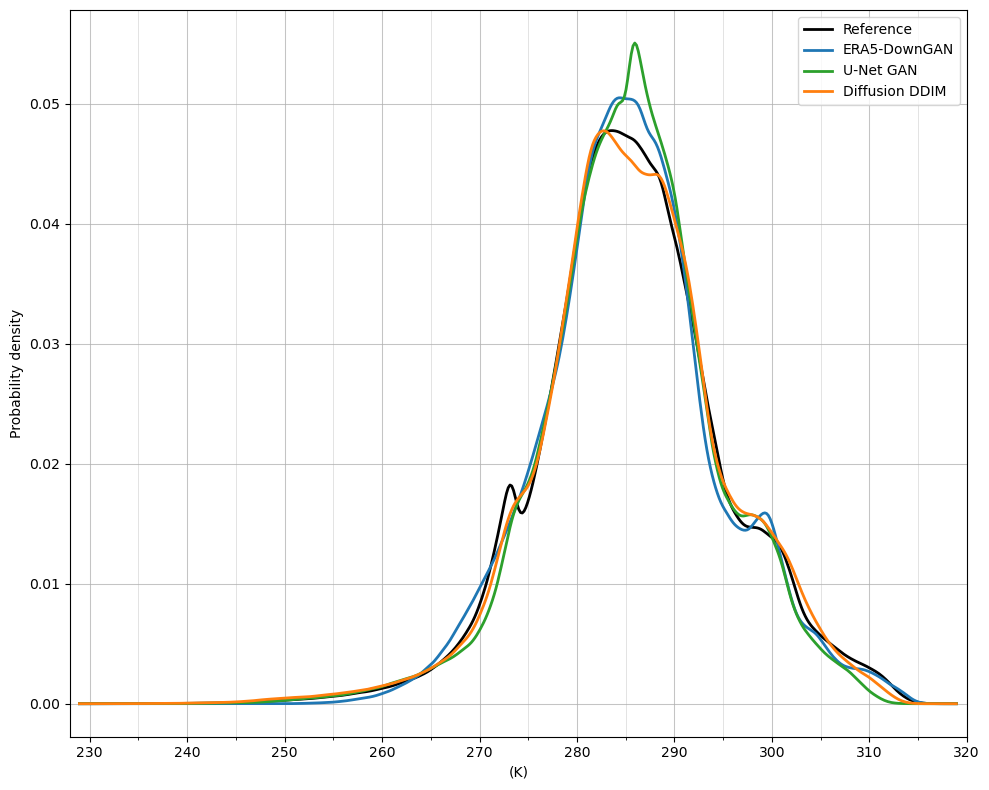

In [6]:
fig, ax = plot_temperature_distributions(
    datasets,
    n_samples=5000000,
    config=plot_config
)

In [7]:
fig.savefig(
    OUTPUT_DIR / "pdf.png",
    dpi=300,
    bbox_inches="tight"
)

## Temperature Distribution Tails

In [8]:
from src.plotting import plot_temperature_tails

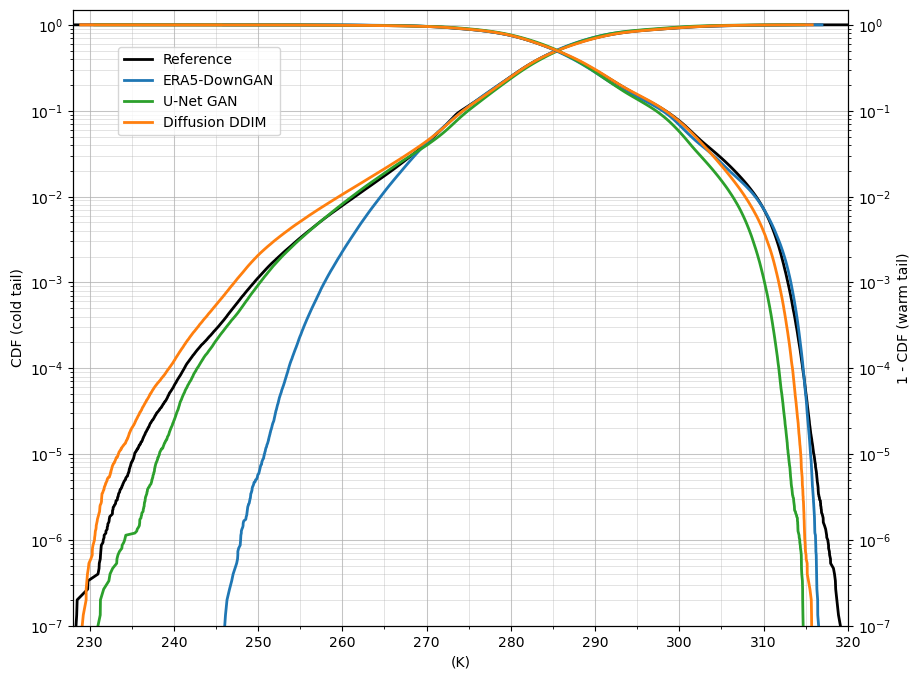

In [9]:
fig, axes = plot_temperature_tails(
    datasets,
    n_samples=15000000,
    figsize=(10, 8),
    config=plot_config
)

In [10]:
fig.savefig(
    OUTPUT_DIR / "distribution_tails.pdf",
    bbox_inches="tight"
)

## PDF and Tail Distributions

In [11]:
from src.plotting import plot_temperature_distribution_tails

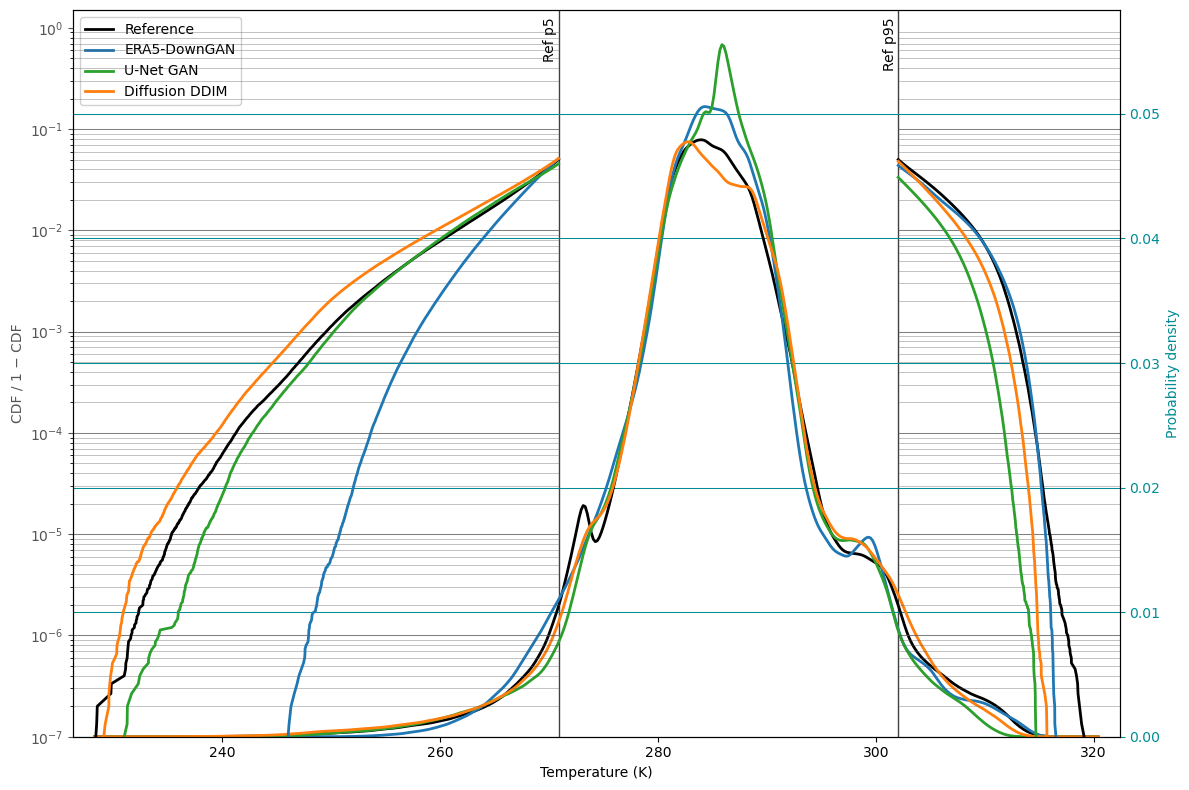

In [12]:
fig, axes = plot_temperature_distribution_tails(datasets,
                                                n_samples=15000000,
                                                figsize=(12, 8),
                                                config=plot_config
                                                )

In [13]:
fig.savefig(
    OUTPUT_DIR / "distribution.png",
    bbox_inches="tight"
)

In [14]:
from matplotlib import pyplot as plt
from src.plotting import add_percentile_lines

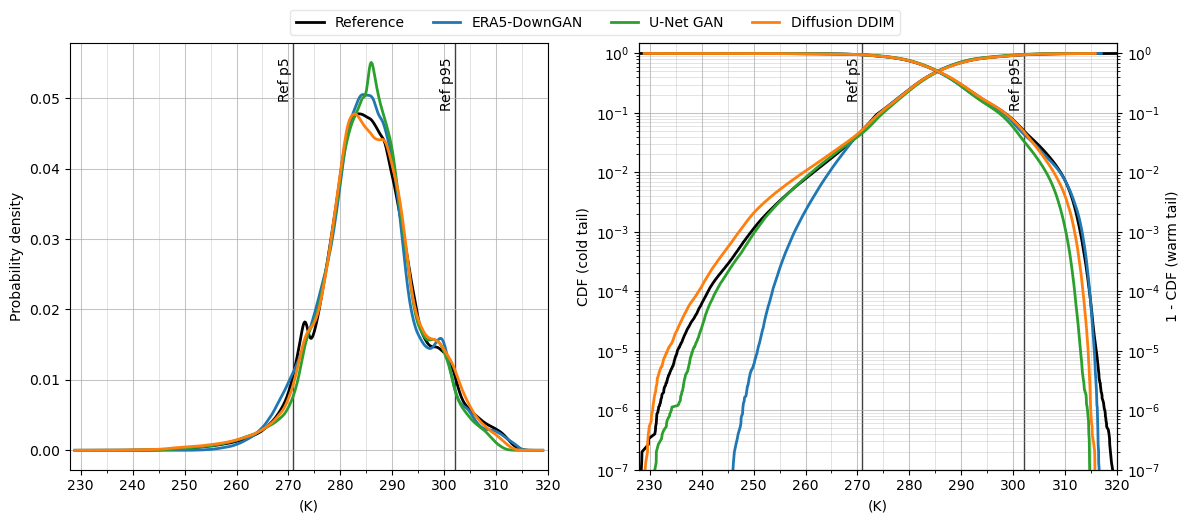

In [15]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

plot_temperature_distributions(
    datasets,
    n_samples=5000000,
    config=plot_config,
    ax=axes[0],
    show_legend=False
)

add_percentile_lines(
    axes[0],
    datasets["reference"],
    percentiles=(5, 95),
    labels=("Ref p5", "Ref p95")
)

plot_temperature_tails(
    datasets,
    n_samples=15000000,
    config=plot_config,
    ax=axes[1],
    show_legend=False
)

add_percentile_lines(
    axes[1],
    datasets["reference"],
    percentiles=(5, 95),
    labels=("Ref p5", "Ref p95")
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(labels),
    bbox_to_anchor=(0.5, 1.05),
    frameon=True,
    facecolor="white",
    framealpha=1,
    edgecolor="0.9"
)

fig.tight_layout()

In [16]:
fig.savefig(
    OUTPUT_DIR / "distribution_panel.png",
    bbox_inches="tight"
)

## QQ plot

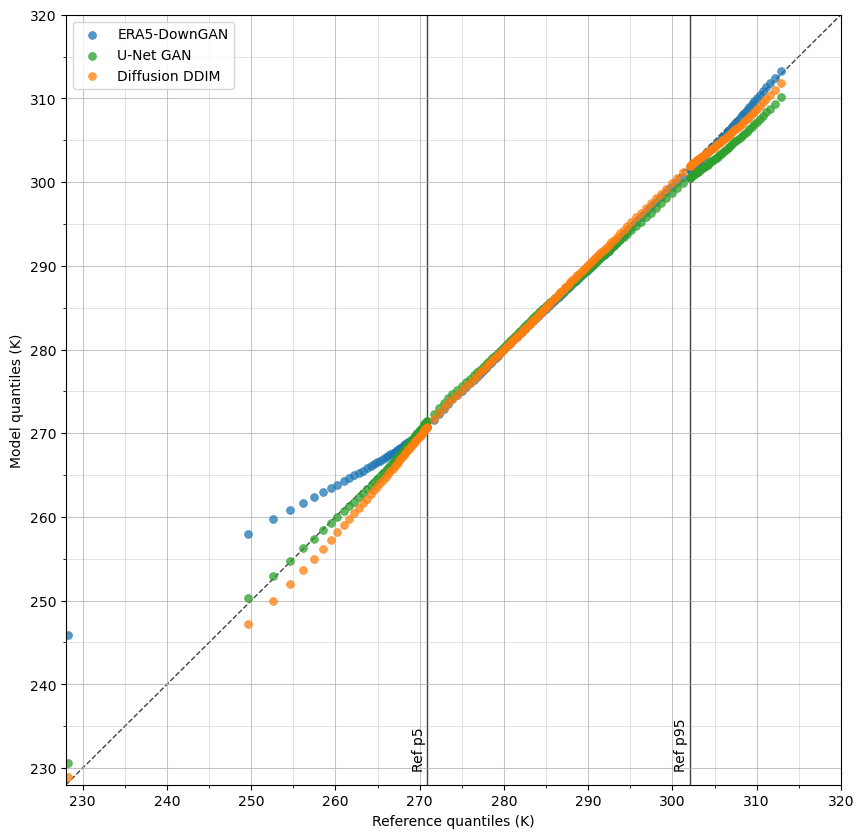

In [17]:
from src.plotting import plot_temperature_qq

fig, ax = plot_temperature_qq(
    datasets,
    n_samples=15000000,
    config=plot_config
)

In [18]:
fig.savefig(
    OUTPUT_DIR / "qq.png",
    dpi=300,
    bbox_inches="tight"
)